# OLA Ride Insights: EDA & Preprocessing
**Labmentix Project 8 · Vipsa Patel**
Data: OLA rides, Bengaluru, 1–31 July 2024 (sheet `July`)

## 1. Data Understanding

In [1]:
# Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

pd.set_option("display.max_columns", None)   # show every column
pd.set_option("display.width", 200)

# Load ONLY the 'July' sheet (Sheet1/Sheet2 are scratch sheets)
URL = "https://raw.githubusercontent.com/Vipsa2207/Ola-Ride-Insights/main/data/raw/OLA_DataSet.xlsx"
df = pd.read_excel(URL, sheet_name="July")

print("Shape:", df.shape)
df.head()

Shape: (103024, 20)


,Date,Time,Booking_ID,Booking_Status,Customer_ID,Vehicle_Type,Pickup_Location,Drop_Location,V_TAT,C_TAT,Canceled_Rides_by_Customer,Canceled_Rides_by_Driver,Incomplete_Rides,Incomplete_Rides_Reason,Booking_Value,Payment_Method,Ride_Distance,Driver_Ratings,Customer_Rating,Vehicle Images
0,2024-07-26 14:00:00,14:00:00,CNR7153255142,Canceled by Driver,CID713523,Prime Sedan,Tumkur Road,RT Nagar,NaN,NaN,NaN,Personal & Car related issue,NaN,NaN,444,NaN,0,NaN,NaN,https://cdn-icons-png.flaticon.com/128/14183/1...
1,2024-07-25 22:20:00,22:20:00,CNR2940424040,Success,CID225428,Bike,Magadi Road,Varthur,203.0,30.0,NaN,NaN,No,NaN,158,Cash,13,4.1,4.0,https://cdn-icons-png.flaticon.com/128/9983/99...
2,2024-07-30 19:59:00,19:59:00,CNR2982357879,Success,CID270156,Prime SUV,Sahakar Nagar,Varthur,238.0,130.0,NaN,NaN,No,NaN,386,UPI,40,4.2,4.8,https://cdn-icons-png.flaticon.com/128/9983/99...
3,2024-07-22 03:15:00,03:15:00,CNR2395710036,Canceled by Customer,CID581320,eBike,HSR Layout,Vijayanagar,NaN,NaN,Driver is not moving towards pickup location,NaN,NaN,NaN,384,NaN,0,NaN,NaN,https://cdn-icons-png.flaticon.com/128/6839/68...
4,2024-07-02 09:02:00,09:02:00,CNR1797421769,Success,CID939555,Mini,Rajajinagar,Chamarajpet,252.0,80.0,NaN,NaN,No,NaN,822,Credit Card,45,4.0,3.0,https://cdn-icons-png.flaticon.com/128/3202/32...


In [2]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 103024 entries, 0 to 103023
Data columns (total 20 columns):
 #   Column                      Non-Null Count   Dtype         
---  ------                      --------------   -----         
 0   Date                        103024 non-null  datetime64[ns]
 1   Time                        103024 non-null  object        
 2   Booking_ID                  103024 non-null  object        
 3   Booking_Status              103024 non-null  object        
 4   Customer_ID                 103024 non-null  object        
 5   Vehicle_Type                103024 non-null  object        
 6   Pickup_Location             103024 non-null  object        
 7   Drop_Location               103024 non-null  object        
 8   V_TAT                       63967 non-null   float64       
 9   C_TAT                       63967 non-null   float64       
 10  Canceled_Rides_by_Customer  10499 non-null   object        
 11  Canceled_Rides_by_Driver    18434 non-n

**Summary:** The July sheet has 103,024 bookings and 20 columns covering Bengaluru, 1–31 July 2024. Date already holds the full date and time, so Time repeats it, and Vehicle Images only stores icon links, so neither is needed for analysis. Six columns (V_TAT, C_TAT, Incomplete_Rides, Payment_Method, Driver_Ratings, Customer_Rating) are filled for exactly 63,967 rows, which is the number of successful rides. This tells us the gaps are structural: a cancelled ride has no trip time, payment or rating, so these blanks are expected and must not be dropped or filled with averages. The two cancellation-reason columns are filled only for their own cancellation type (10,499 customer and 18,434 driver), and Incomplete_Rides_Reason only for the 3,926 incomplete rides. Action: treat these nulls as “not applicable” rather than as errors, and clean column names before loading the data into MySQL.

## 2. Data Quality Checks
### 2.1 Missing values: are they structural?

In [3]:
# Count nulls per column
nulls = df.isna().sum().to_frame("Null_Count")
nulls["Null_%"] = (nulls["Null_Count"] / len(df) * 100).round(2)
print(nulls[nulls["Null_Count"] > 0])

# Proof: among SUCCESS rides, the 6 key columns should have ZERO nulls
key_cols = ["V_TAT","C_TAT","Payment_Method","Incomplete_Rides","Driver_Ratings","Customer_Rating"]
print("\nNulls inside Success rides:")
print(df.loc[df["Booking_Status"]=="Success", key_cols].isna().sum())

                            Null_Count  Null_%
V_TAT                            39057   37.91
C_TAT                            39057   37.91
Canceled_Rides_by_Customer       92525   89.81
Canceled_Rides_by_Driver         84590   82.11
Incomplete_Rides                 39057   37.91
Incomplete_Rides_Reason          99098   96.19
Payment_Method                   39057   37.91
Driver_Ratings                   39057   37.91
Customer_Rating                  39057   37.91

Nulls inside Success rides:
V_TAT               0
C_TAT               0
Payment_Method      0
Incomplete_Rides    0
Driver_Ratings      0
Customer_Rating     0
dtype: int64


**Insight:** Six columns are 37.91% empty (39,057 rows each), but none of those blanks fall on successful rides. Every blank belongs to a cancelled or “Driver Not Found” booking. The reason columns are even emptier (82–96%), because each is filled only for its own event type.

**So what:** these are not data errors. A ride that never happened has no trip time, no payment and no rating. Dropping these rows would delete 38% of bookings and hide the entire cancellation problem. Filling ratings with the average would invent fake 4.0 ratings for rides that never took place.

**Action:** keep every row, fill the text columns with “Not Applicable”, leave the numeric columns blank (NULL), and calculate ratings, distance and payment metrics on successful rides only.

### 2.2 Duplicates, unique IDs and redundant columns

In [4]:
# Exact duplicate rows
print("Duplicate rows:", df.duplicated().sum())

# Is every Booking_ID unique?
print("Unique Booking_IDs:", df["Booking_ID"].nunique(), "of", len(df))

# Is 'Time' just a copy of the time part inside 'Date'?
same_time = df["Date"].dt.strftime("%H:%M:%S") == df["Time"].astype(str)
print("Time matches Date's time part:", same_time.sum(), "of", len(df))

Duplicate rows: 0
Unique Booking_IDs: 103024 of 103024
Time matches Date's time part: 103024 of 103024


**Insight:** The data has no duplicate rows, and all 103,024 Booking_IDs are unique, so each row is exactly one booking. The Time column matches the time part of Date on every single row.

**So what:** we can trust row counts as booking counts without any de-duplication, and Time adds nothing except the risk of the two columns drifting apart later.

**Action:** use Booking_ID as the primary key in MySQL (a primary key is the column that uniquely identifies each row), and drop Time during cleaning, keeping Date as the single source of date and time.

### 2.3 Category consistency and numeric ranges

In [5]:
cat_cols = ["Booking_Status","Vehicle_Type","Payment_Method","Incomplete_Rides",
            "Canceled_Rides_by_Customer","Canceled_Rides_by_Driver","Incomplete_Rides_Reason"]

for c in cat_cols:
    print(f"\n--- {c} ---")
    print(df[c].value_counts(dropna=False))

# Any text with extra spaces at the start or end?
obj_cols = df.select_dtypes("object").columns.drop("Time")
spaces = {c: (df[c].dropna().astype(str) != df[c].dropna().astype(str).str.strip()).sum() for c in obj_cols}
print("\nValues with leading/trailing spaces:", {k: v for k, v in spaces.items() if v > 0} or "None")


--- Booking_Status ---
Booking_Status
Success                 63967
Canceled by Driver      18434
Canceled by Customer    10499
Driver Not Found        10124
Name: count, dtype: int64

--- Vehicle_Type ---
Vehicle_Type
Prime Sedan    14877
eBike          14816
Auto           14755
Prime Plus     14707
Bike           14662
Prime SUV      14655
Mini           14552
Name: count, dtype: int64

--- Payment_Method ---
Payment_Method
NaN            39057
Cash           35022
UPI            25881
Credit Card     2435
Debit Card       629
Name: count, dtype: int64

--- Incomplete_Rides ---
Incomplete_Rides
No     60041
NaN    39057
Yes     3926
Name: count, dtype: int64

--- Canceled_Rides_by_Customer ---
Canceled_Rides_by_Customer
NaN                                             92525
Driver is not moving towards pickup location     3175
Driver asked to cancel                           2670
Change of plans                                  2081
AC is Not working                                1

In [6]:
df[["V_TAT","C_TAT","Booking_Value","Ride_Distance","Driver_Ratings","Customer_Rating"]].describe().round(2)

,V_TAT,C_TAT,Booking_Value,Ride_Distance,Driver_Ratings,Customer_Rating
count,63967.00,63967.00,103024.00,103024.00,63967.00,63967.00
mean,170.88,84.87,548.75,14.19,4.00,4.00
std,80.80,36.01,536.54,15.78,0.58,0.58
min,35.00,25.00,100.00,0.00,3.00,3.00
25%,98.00,55.00,242.00,0.00,3.50,3.50
50%,168.00,85.00,386.00,8.00,4.00,4.00
75%,238.00,115.00,621.00,26.00,4.50,4.50
max,308.00,145.00,2999.00,49.00,5.00,5.00


**Insight:** All category columns are clean: 4 booking statuses, 7 vehicle types, 4 payment methods and fixed reason lists, with no spelling variants or stray spaces, and every category total matches its parent count exactly. Only 62.1% of bookings succeed. The rest are 17.9% cancelled by drivers, 10.2% cancelled by customers and 9.8% “Driver Not Found”. Cash covers 54.8% of successful payments and UPI 40.5%, while cards are under 5%. Ratings sit strictly between 3.0 and 5.0, with an average of exactly 4.00 for both drivers and customers, and the 7 vehicle types each hold about 14% of bookings. This very even spread suggests the data is synthetic (artificially generated rather than real). Booking_Value is right-skewed (mean ₹549 vs median ₹386), and Ride_Distance has a median of only 8 km, because cancelled rides are stored as 0 km. TAT units are not documented, so we report them as given.

**So what:** no text cleaning is needed, but any average calculated over all rows will be wrong.

**Action:** calculate distance, rating and payment metrics on successful rides only, treat Booking_Value on cancelled rides as a quoted fare (not revenue), and report “no meaningful difference” honestly wherever the even synthetic spread shows up.

## 3. Data Cleaning
Steps: (1) save vehicle icons as a lookup table, (2) drop redundant `Time`,
(3) rename `Vehicle Images`, (4) fill text nulls with "Not Applicable",
(5) keep numeric nulls as NaN (structural, not missing).

In [7]:
clean = df.copy()   # keep the raw df untouched

# 1. Icon lookup table: one icon URL per vehicle type
icons = (clean[["Vehicle_Type", "Vehicle Images"]]
         .drop_duplicates()
         .rename(columns={"Vehicle Images": "Icon_URL"}))
print("Icon rows:", len(icons))   # expect 7

# 2 + 3. Drop Time and the icon column (icons now live in the lookup table)
clean = clean.drop(columns=["Time", "Vehicle Images"])

# 4. Fill TEXT nulls with "Not Applicable"
text_cols = ["Canceled_Rides_by_Customer", "Canceled_Rides_by_Driver",
             "Incomplete_Rides", "Incomplete_Rides_Reason", "Payment_Method"]
clean[text_cols] = clean[text_cols].fillna("Not Applicable")

# 5. Numeric nulls stay NaN. Confirm what is left:
print("Shape:", clean.shape)
print(clean.isna().sum()[clean.isna().sum() > 0])

Icon rows: 7
Shape: (103024, 18)
V_TAT              39057
C_TAT              39057
Driver_Ratings     39057
Customer_Rating    39057
dtype: int64


**Insight:** Cleaning removed two columns and changed no data values. Time was dropped because it matched Date on all 103,024 rows. The Vehicle Images URLs were moved into a 7-row icon lookup table, one icon per vehicle type, instead of being repeated on 103,024 rows. Five text columns (the three reason columns, Incomplete_Rides and Payment_Method) now say “Not Applicable” instead of blank. The four numeric columns (V_TAT, C_TAT, Driver_Ratings, Customer_Rating) keep their 39,057 blanks on purpose.

**So what:** the table is now lighter and free of SQL-unfriendly column names, and charts and filters will show a clear “Not Applicable” label instead of a confusing empty value. No row was deleted, and no rating was invented.

**Action:** load this cleaned table and the icon lookup table into MySQL as separate tables, and keep numeric blanks as NULL so averages automatically skip non-completed rides.

## 4. Feature Engineering
### 4.1 Time features

In [8]:
clean = clean.rename(columns={"Date": "Booking_DateTime"})
dt = clean["Booking_DateTime"]

clean["Ride_Date"]  = dt.dt.date
clean["Ride_Hour"]  = dt.dt.hour
clean["Day_Name"]   = dt.dt.day_name()
clean["Week_No"]    = (dt.dt.day - 1) // 7 + 1          # week of July: 1–5
clean["Is_Weekend"] = dt.dt.dayofweek >= 5               # Sat/Sun = True

def time_slot(h):
    if 5 <= h < 12:  return "Morning"
    if 12 <= h < 17: return "Afternoon"
    if 17 <= h < 21: return "Evening"
    return "Night"                                        # 21:00–04:59
clean["Time_Slot"] = clean["Ride_Hour"].apply(time_slot)

print(clean["Time_Slot"].value_counts())
print(clean["Week_No"].value_counts().sort_index())

Time_Slot
Night        34268
Morning      30166
Afternoon    21562
Evening      17028
Name: count, dtype: int64
Week_No
1    23181
2    23386
3    23236
4    23347
5     9874
Name: count, dtype: int64


### 4.2 Business features

In [9]:
s = clean["Booking_Status"]
clean["Is_Success"] = (s == "Success").astype(int)

clean["Cancelled_By"] = s.map({"Canceled by Customer": "Customer",
                               "Canceled by Driver":   "Driver",
                               "Driver Not Found":     "System - Driver Not Found",
                               "Success":              "None"})

# One merged reason column
clean["Cancellation_Reason"] = np.select(
    [s == "Canceled by Customer", s == "Canceled by Driver", s == "Driver Not Found"],
    [clean["Canceled_Rides_by_Customer"], clean["Canceled_Rides_by_Driver"], "Driver Not Found"],
    default="Not Applicable")

# Revenue = money actually earned (successful rides only)
clean["Revenue"] = np.where(clean["Is_Success"] == 1, clean["Booking_Value"], 0)

# Fare per km: only for successful rides with distance > 0
ok = (clean["Is_Success"] == 1) & (clean["Ride_Distance"] > 0)
clean["Fare_per_km"] = np.where(ok, clean["Booking_Value"] / clean["Ride_Distance"], np.nan).round(2)

# Distance band (successful rides only)
clean["Distance_Band"] = pd.cut(clean["Ride_Distance"], bins=[0, 5, 10, 20, 30, 50],
                                labels=["1-5 km", "6-10 km", "11-20 km", "21-30 km", "31-50 km"]).astype(str)
clean.loc[clean["Is_Success"] == 0, "Distance_Band"] = "Not Applicable"

clean["Rating_Gap"]       = (clean["Driver_Ratings"] - clean["Customer_Rating"]).round(2)
clean["Route"]            = clean["Pickup_Location"] + " → " + clean["Drop_Location"]
clean["Same_Pickup_Drop"] = (clean["Pickup_Location"] == clean["Drop_Location"]).astype(int)

print("Shape:", clean.shape)
print(clean["Cancelled_By"].value_counts())
print(clean["Distance_Band"].value_counts())
print("Success rides with distance 0:", ((clean["Is_Success"]==1) & (clean["Ride_Distance"]==0)).sum())
print("Same pickup & drop:", clean["Same_Pickup_Drop"].sum())
print("Revenue total: ₹", clean["Revenue"].sum())

Shape: (103024, 33)
Cancelled_By
None                         63967
Driver                       18434
Customer                     10499
System - Driver Not Found    10124
Name: count, dtype: int64
Distance_Band
Not Applicable    39057
31-50 km          21325
11-20 km          15517
21-30 km          11131
1-5 km             8042
6-10 km            7952
Name: count, dtype: int64
Success rides with distance 0: 0
Same pickup & drop: 2121
Revenue total: ₹ 35080467


**Insight:** 15 features were added (33 columns in total), and every new column reconciles with the raw counts: Cancelled_By matches the four booking statuses exactly, distance bands cover all 63,967 successful rides with no zero-distance trips, and total revenue from successful rides is ₹3,50,80,467 (≈ ₹3.51 Cr). The raw slot counts suggest Night is busiest (34,268 rides), but Night spans 8 hours and Evening only 4. Per hour, all four slots carry a nearly identical 4,257–4,312 rides. In the same way, Week 5 is small only because it has 3 days (≈3,291 rides/day vs ≈3,320/day in Weeks 1–4). 2,121 bookings (2.1%) have the same pickup and drop location, which is unusual for a taxi trip.

**So what:** comparing raw totals across unequal time windows gives false conclusions, and demand is in fact flat across the day and month.

**Action:** always compare demand per hour or per day rather than by raw totals, use ₹3.51 Cr as the single revenue figure that SQL, Power BI and Streamlit must match, and investigate the same-location trips as a data-quality or fraud anomaly in the EDA.

## 5. Exploratory Data Analysis
### 5.1 Univariate analysis (one variable at a time)
#### Chart 1: Booking status breakdown

In [11]:
sns.set_theme(style="whitegrid")
OLA_GREEN, OLA_BLACK = "#B5D334", "#1C1C1C"
STATUS_COLORS = {"Success": "#2E8B57", "Canceled by Driver": "#E4572E",
                 "Canceled by Customer": "#F3A712", "Driver Not Found": "#7F7F7F"}
success = clean[clean["Is_Success"] == 1]      # shortcut: successful rides only
print("Successful rides:", len(success))

Successful rides: 63967


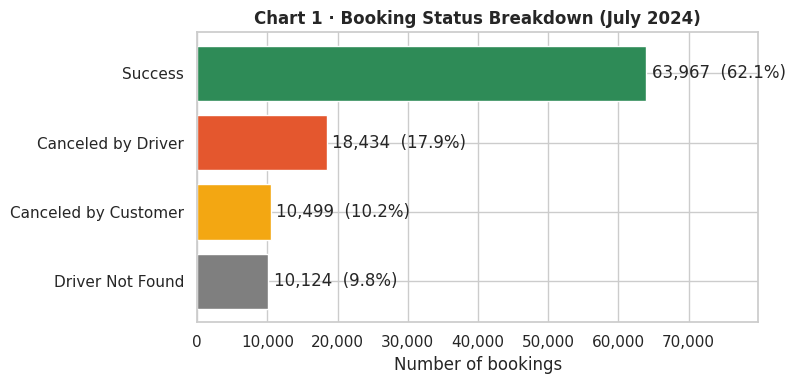

In [13]:
counts = clean["Booking_Status"].value_counts()
pct = (counts / counts.sum() * 100).round(1)

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.barh(counts.index, counts.values, color=[STATUS_COLORS[s] for s in counts.index])
ax.bar_label(bars, labels=[f"{v:,}  ({p}%)" for v, p in zip(counts, pct)], padding=4)
ax.invert_yaxis()                               # biggest bar on top
ax.set_title("Chart 1 · Booking Status Breakdown (July 2024)", weight="bold")
ax.set_xlabel("Number of bookings")
ax.set_xlim(0, counts.max() * 1.25)             # room for labels
plt.tight_layout();
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:,.0f}"))
plt.show()

**Insight:** Only 62.1% of July bookings (63,967) became completed rides. Drivers cancelled 17.9% (18,434), customers cancelled 10.2% (10,499), and 9.8% (10,124) failed because no driver was found. That gives a cancellation rate of 28.1%, plus a 9.8% supply gap. Drivers cancel about 1.76 times as often as customers.

**So what:** nearly 4 in 10 ride requests produce no revenue, and the biggest single leak is on the driver side, not the customer side, so customer-focused fixes alone will not solve the problem.

**Action:** make driver cancellations the top priority (study the driver reasons in the cancellation charts and add penalties or incentives for acceptance), and treat “Driver Not Found” as a separate supply problem to fix with better driver positioning and surge incentives in low-coverage areas.

#### Chart 2: Ride demand by hour of day

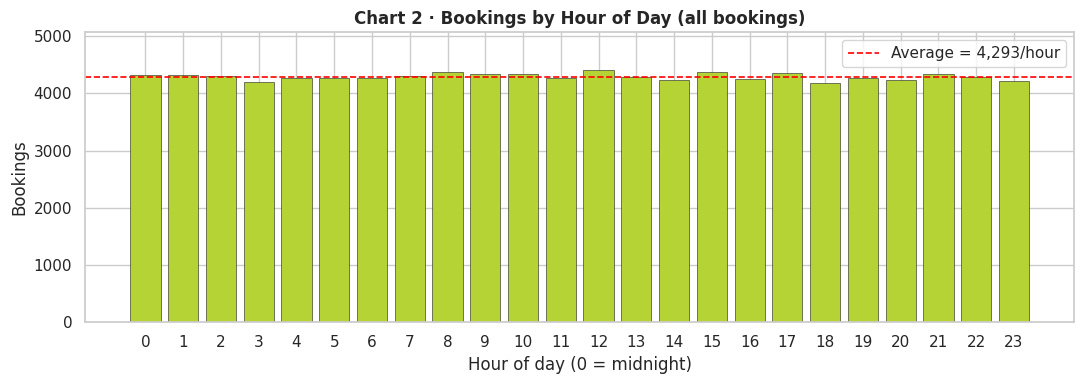

Peak hour: 12 → 4408 | Lowest hour: 18 → 4176
Peak vs lowest difference: 5.6%


In [14]:
hourly = clean["Ride_Hour"].value_counts().sort_index()   # bookings for each hour 0–23
avg = hourly.mean()

fig, ax = plt.subplots(figsize=(11, 4))
ax.bar(hourly.index, hourly.values, color=OLA_GREEN, edgecolor=OLA_BLACK, linewidth=0.4)
ax.axhline(avg, color="red", ls="--", lw=1.2, label=f"Average = {avg:,.0f}/hour")
ax.set_xticks(range(24))
ax.set_title("Chart 2 · Bookings by Hour of Day (all bookings)", weight="bold")
ax.set_xlabel("Hour of day (0 = midnight)"); ax.set_ylabel("Bookings")
ax.set_ylim(0, hourly.max() * 1.15); ax.legend()
plt.tight_layout(); plt.show()

print("Peak hour:", hourly.idxmax(), "→", hourly.max(), "| Lowest hour:", hourly.idxmin(), "→", hourly.min())
print("Peak vs lowest difference: {:.1f}%".format((hourly.max() / hourly.min() - 1) * 100))

**Insight:** Bookings are almost perfectly flat across the 24 hours, averaging 4,293 per hour. The busiest hour (12:00, 4,408 bookings) is only 5.6% above the quietest (18:00, 4,176). There is no morning or evening rush, and 6 PM, normally a commute peak in Bengaluru, is actually the lowest hour.

**So what:** this dataset gives no evidence for time-based peaks, so planning surge pricing or extra driver shifts around “rush hours” would not be supported by these numbers. The uniform pattern also confirms that the data is synthetic.

**Action:** keep driver supply evenly spread across all 24 hours for this dataset, report “no meaningful peak hour” honestly, and recommend validating peak-hour planning with real trip data before using it for surge pricing or shift scheduling.

#### Chart 3: Average daily bookings by day of week

           Avg_per_day  Days_in_July
Day_Name                            
Monday          3346.0             5
Tuesday         3385.0             5
Wednesday       3287.0             5
Thursday        3309.0             4
Friday          3336.0             4
Saturday        3335.0             4
Sunday          3253.0             4


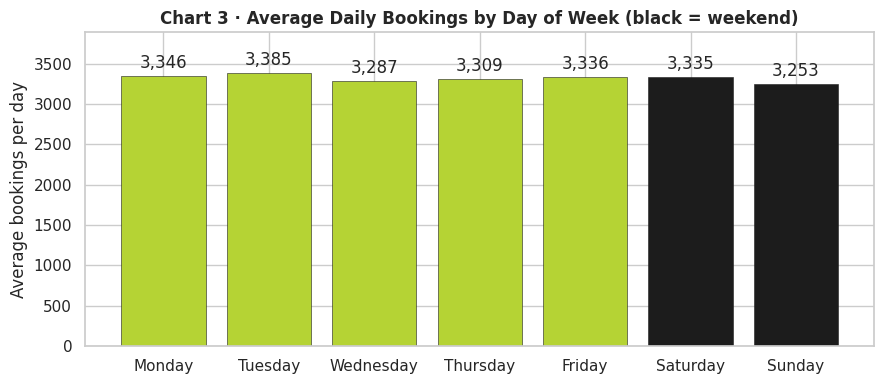

In [15]:
order = ["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]

daily = clean.groupby("Ride_Date").size().rename("Bookings").reset_index()   # bookings per calendar day
daily["Day_Name"] = pd.to_datetime(daily["Ride_Date"]).dt.day_name()

by_day = daily.groupby("Day_Name")["Bookings"].agg(["mean", "count"]).reindex(order)
print(by_day.rename(columns={"mean": "Avg_per_day", "count": "Days_in_July"}).round(0))

fig, ax = plt.subplots(figsize=(9, 4))
colors = [OLA_BLACK if d in ["Saturday", "Sunday"] else OLA_GREEN for d in order]
bars = ax.bar(order, by_day["mean"], color=colors, edgecolor=OLA_BLACK, linewidth=0.4)
ax.bar_label(bars, labels=[f"{v:,.0f}" for v in by_day["mean"]], padding=3)
ax.set_title("Chart 3 · Average Daily Bookings by Day of Week (black = weekend)", weight="bold")
ax.set_ylabel("Average bookings per day")
ax.set_ylim(0, by_day["mean"].max() * 1.15)
plt.tight_layout(); plt.show()

**Insight:** After adjusting for the fact that July 2024 had five Mondays, Tuesdays and Wednesdays but only four of the other days, average daily bookings are almost identical across the week, ranging from 3,253 (Sunday) to 3,385 (Tuesday), a gap of just 4.1%. Weekends average about 3,294 bookings per day against about 3,334 on weekdays, only 1.2% lower.

**So what:** there is no weekday-vs-weekend demand effect in this data, so separate weekend pricing or weekend-only driver schedules are not justified by these numbers. The adjustment also shows why raw totals mislead: without it, Monday to Wednesday would have looked about 25% busier simply because they occurred more often.

**Action:** plan driver supply evenly across all seven days for this dataset, always compare days using averages per occurrence, and revisit weekday/weekend strategy once real multi-month data is available.**bold text**

#### Chart 4: Bookings by vehicle type

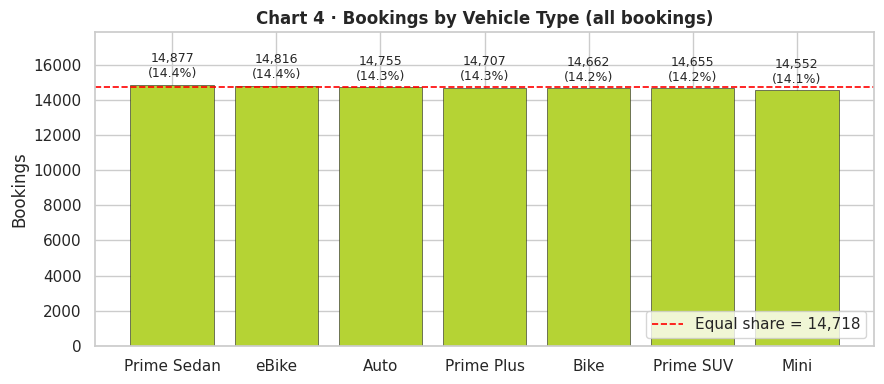

Most booked: Prime Sedan 14877 | Least: Mini 14552 | Gap: 2.2%


In [16]:
veh = clean["Vehicle_Type"].value_counts()
veh_pct = (veh / veh.sum() * 100).round(1)

fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.bar(veh.index, veh.values, color=OLA_GREEN, edgecolor=OLA_BLACK, linewidth=0.4)
ax.bar_label(bars, labels=[f"{v:,}\n({p}%)" for v, p in zip(veh, veh_pct)], padding=3, fontsize=9)
ax.axhline(veh.mean(), color="red", ls="--", lw=1.2, label=f"Equal share = {veh.mean():,.0f}")
ax.set_title("Chart 4 · Bookings by Vehicle Type (all bookings)", weight="bold")
ax.set_ylabel("Bookings"); ax.set_ylim(0, veh.max() * 1.2); ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

print("Most booked:", veh.idxmax(), veh.max(), "| Least:", veh.idxmin(), veh.min(),
      "| Gap: {:.1f}%".format((veh.max() / veh.min() - 1) * 100))

**Insight:** All seven vehicle types receive almost exactly the same share of bookings, between 14.1% and 14.4% each, close to the equal share of 14,718. Prime Sedan is the most booked (14,877) and Mini the least (14,552), but the gap between them is only 2.2%. Premium cars (Prime Sedan, Prime SUV, Prime Plus) are booked as often as budget options (Bike, Auto, Mini).

**So what:** booking volume alone gives no reason to favour or cut any vehicle category. A real ride-hailing market would almost never show such an even split between cheap two-wheelers and premium SUVs, which again confirms the data is synthetic.

**Action:** keep fleet allocation balanced across all seven types for now, and judge vehicle performance on success rate, revenue and ratings (the next charts) rather than on booking volume, where they all look the same.

#### Chart 5: Payment method share (successful rides)

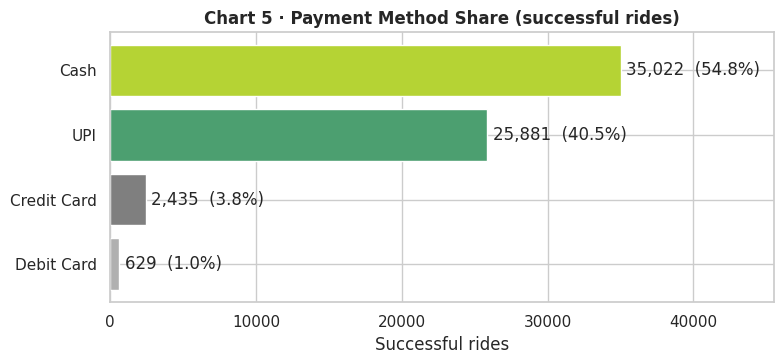

Total checked: 63967 (should be 63,967)


In [17]:
pay = success["Payment_Method"].value_counts()
pay_pct = (pay / pay.sum() * 100).round(1)

fig, ax = plt.subplots(figsize=(8, 3.8))
bars = ax.barh(pay.index, pay.values, color=[OLA_GREEN, "#4C9F70", "#7F7F7F", "#B0B0B0"])
ax.bar_label(bars, labels=[f"{v:,}  ({p}%)" for v, p in zip(pay, pay_pct)], padding=4)
ax.invert_yaxis()
ax.set_title("Chart 5 · Payment Method Share (successful rides)", weight="bold")
ax.set_xlabel("Successful rides"); ax.set_xlim(0, pay.max() * 1.3)
plt.tight_layout(); plt.show()

print("Total checked:", pay.sum(), "(should be 63,967)")

**Insight:** Among the 63,967 successful rides, Cash is the most used payment method (35,022 rides, 54.8%), followed closely by UPI (25,881, 40.5%). Cards are rarely used: Credit Card accounts for 3.8% (2,435) and Debit Card only 1.0% (629). Together, Cash and UPI cover 95.3% of all completed rides. Unlike demand by hour, day or vehicle, this is a clear and uneven pattern.

**So what:** OLA’s revenue collection depends heavily on cash, which brings handling costs, change disputes and slower reconciliation for drivers, while UPI is already a strong digital alternative. Cards are almost unused, so card-focused offers would have very little impact.

**Action:** run UPI cashback or loyalty incentives to move cash riders to UPI, which speeds up settlement and reduces driver cash risk, keep cash available because over half of riders still rely on it, and avoid spending marketing budget on card-specific promotions.

#### Chart 6: Booking value distribution (successful rides)

count    63967.0
mean       548.4
std        536.7
min        100.0
25%        242.0
50%        385.0
75%        622.0
max       2999.0
Name: Booking_Value, dtype: float64
Skewness: 2.58


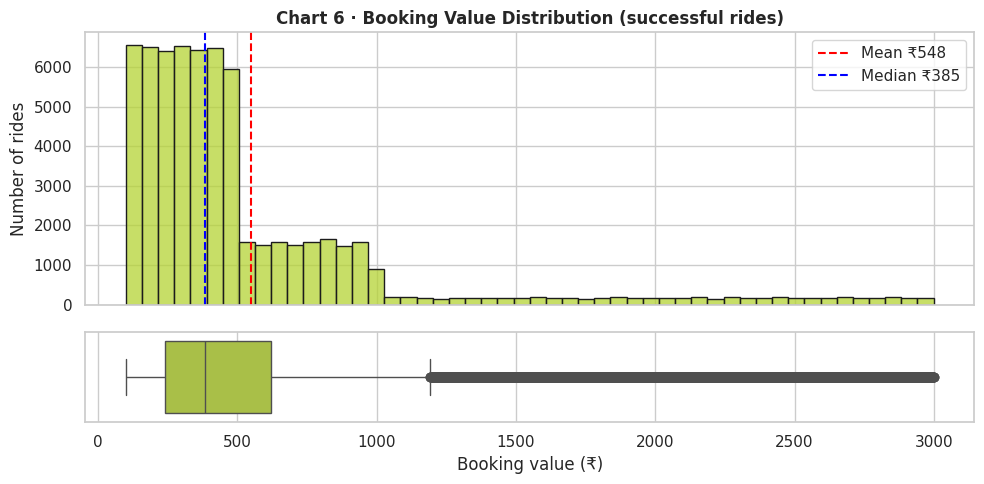

In [18]:
bv = success["Booking_Value"]
print(bv.describe().round(1))
print("Skewness:", round(bv.skew(), 2))

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 5), sharex=True,
                               gridspec_kw={"height_ratios": [3, 1]})
sns.histplot(bv, bins=50, color=OLA_GREEN, edgecolor=OLA_BLACK, ax=ax1)
ax1.axvline(bv.mean(),   color="red",  ls="--", label=f"Mean ₹{bv.mean():,.0f}")
ax1.axvline(bv.median(), color="blue", ls="--", label=f"Median ₹{bv.median():,.0f}")
ax1.set_title("Chart 6 · Booking Value Distribution (successful rides)", weight="bold")
ax1.set_ylabel("Number of rides"); ax1.legend()
sns.boxplot(x=bv, color=OLA_GREEN, ax=ax2)
ax2.set_xlabel("Booking value (₹)")
plt.tight_layout(); plt.show()

**Insight:** Fares for completed rides are strongly right-skewed (skewness 2.58). Half of all rides cost ₹385 or less, three-quarters cost ₹622 or less, but a long tail stretches to ₹2,999, which lifts the average fare to ₹548. The distribution falls in three flat steps: most rides are ₹100–500, a smaller group is ₹500–1,000, and a thin, even tail runs from ₹1,000 to ₹3,000. Rides above about ₹1,192 count as statistical outliers.

**So what:** the “average fare” of ₹548 overstates what a typical customer pays, so the median (₹385) is the honest benchmark for pricing decisions. The high-value tail is small in ride count but matters for revenue. The step-like pattern, instead of a smooth curve, is another sign of synthetic data.

**Action:** report the median fare as the typical ride value, keep the high-fare outliers (they are valid long or premium trips, not errors), and later check fare per km to make sure these high fares match long distances rather than pricing mistakes.

#### Chart 7: Ride distance distribution (successful rides)

count    63967.0
mean        22.9
std         14.2
min          1.0
25%         10.0
50%         21.0
75%         35.0
max         49.0
Name: Ride_Distance, dtype: float64
Skewness: 0.22


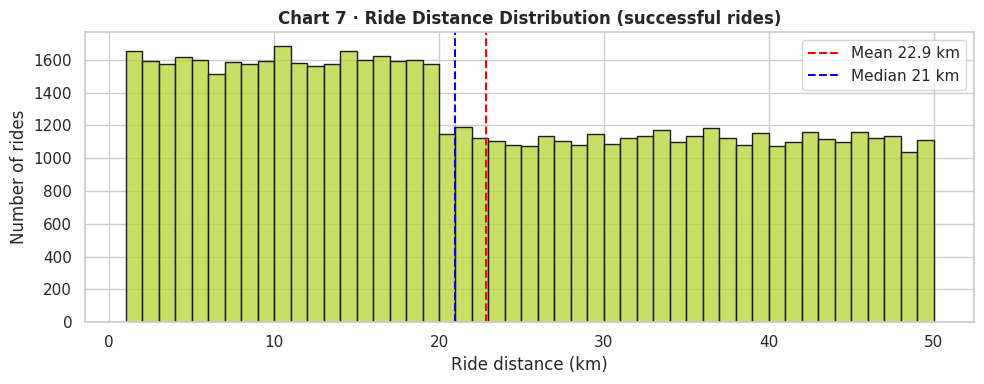

In [19]:
rd = success["Ride_Distance"]
print(rd.describe().round(1))
print("Skewness:", round(rd.skew(), 2))

fig, ax = plt.subplots(figsize=(10, 4))
sns.histplot(rd, bins=range(1, 51), color=OLA_GREEN, edgecolor=OLA_BLACK, ax=ax)   # 1 bar per km
ax.axvline(rd.mean(),   color="red",  ls="--", label=f"Mean {rd.mean():.1f} km")
ax.axvline(rd.median(), color="blue", ls="--", label=f"Median {rd.median():.0f} km")
ax.set_title("Chart 7 · Ride Distance Distribution (successful rides)", weight="bold")
ax.set_xlabel("Ride distance (km)"); ax.set_ylabel("Number of rides"); ax.legend()
plt.tight_layout(); plt.show()

**Insight:** Completed rides range from 1 km to 49 km, with an average of 22.9 km and a median of 21 km. The skewness of 0.22 shows an almost symmetric spread, so the mean is a fair “typical” value here. The distribution has two flat levels: about 1,600 rides per km for trips of 1–20 km, then a sharp drop to about 1,120 rides per km for trips of 21–49 km. Short and long trips are both common, and there is no single “typical” distance.

**So what:** an average of 22.9 km is long for city rides and much higher than the misleading 14.19 km we would get by including cancelled 0 km bookings, which shows why the success-only rule matters. The sudden step at 20 km, instead of a gradual decline, is another synthetic-data signal.

**Action:** use 22.9 km as the official average ride distance across SQL, Power BI and Streamlit, plan fleet and fuel costs for a wide mix of short and long trips rather than one standard trip length, and check later whether long trips earn proportionally more through fare per km.

#### Chart 8: Driver ratings vs customer ratings (successful rides)

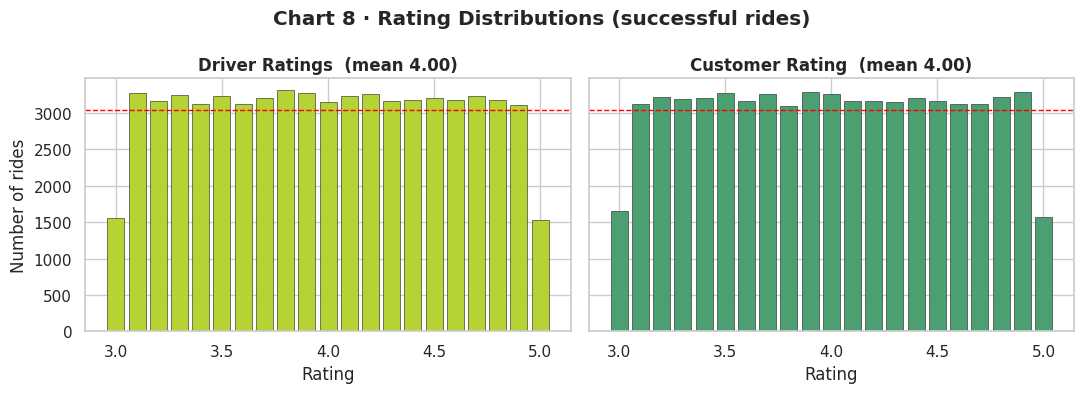

Driver_Ratings | range: 3.0 to 5.0 | distinct values: 21 | median: 4.0
Customer_Rating | range: 3.0 to 5.0 | distinct values: 21 | median: 4.0


In [22]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, col, color in zip(axes, ["Driver_Ratings", "Customer_Rating"], [OLA_GREEN, "#4C9F70"]):
    vc = success[col].value_counts().sort_index()          # count of each rating value
    bars = ax.bar(vc.index, vc.values, width=0.08, color=color, edgecolor=OLA_BLACK, linewidth=0.4)
    ax.set_xticks([3.0, 3.5, 4.0, 4.5, 5.0])
    ax.axhline(vc.mean(), color="red", ls="--", lw=1)
    ax.set_title(f"{col.replace('_', ' ')}  (mean {success[col].mean():.2f})", weight="bold")
    ax.set_xlabel("Rating")
axes[0].set_ylabel("Number of rides")
fig.suptitle("Chart 8 · Rating Distributions (successful rides)", weight="bold")
plt.tight_layout(); plt.show()

for col in ["Driver_Ratings", "Customer_Rating"]:
    print(col, "| range:", success[col].min(), "to", success[col].max(),
          "| distinct values:", success[col].nunique(), "| median:", success[col].median())

**Insight:** Driver ratings and customer ratings have identical distributions. Both run from 3.0 to 5.0 in steps of 0.1, and both have a mean and median of exactly 4.00. Every value between 3.1 and 4.9 has roughly the same number of rides (about 3,150), while the end values 3.0 and 5.0 have only about half as many. This is the typical pattern produced by generating evenly spread random numbers and rounding them. There are no ratings below 3.0, and there is no cluster at 5 stars as real ride apps usually show.

**So what:** ratings here cannot separate good drivers or customers from bad ones, because satisfaction looks the same everywhere and no rider was ever “unhappy” (below 3 stars). Any ranking of drivers by rating would only reflect random noise.

**Action:** report ratings as “uniform with no meaningful variation” rather than inventing differences, avoid using them for driver rewards or penalties in this dataset, and recommend that OLA review its real rating data for the usual 5-star clustering and low-rating complaints before building a rating-based quality programme.

### 5.2 Bivariate analysis (two variables together)
#### Chart 9: Cancellation reasons — customer vs driver

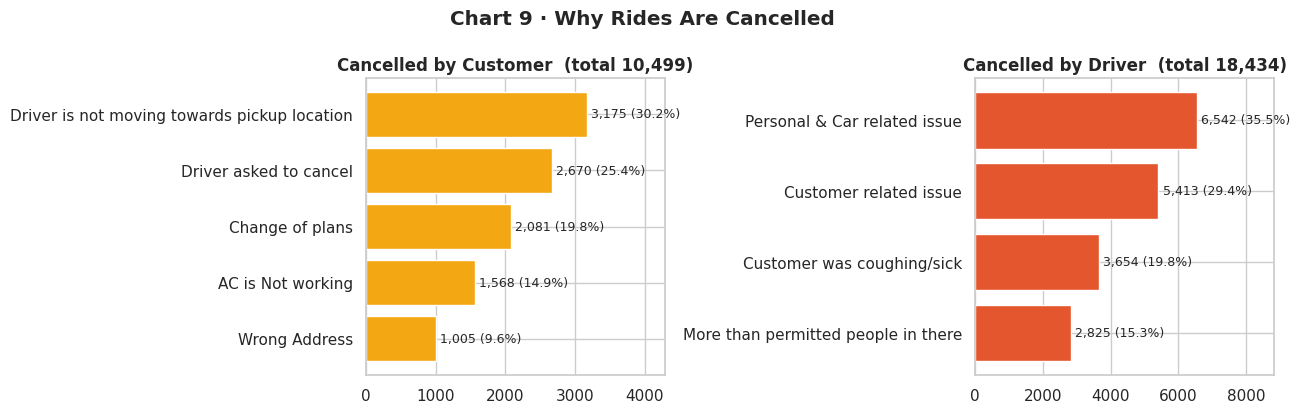

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for ax, who, color in zip(axes, ["Customer", "Driver"], ["#F3A712", "#E4572E"]):
    r = clean.loc[clean["Cancelled_By"] == who, "Cancellation_Reason"].value_counts()
    pct = (r / r.sum() * 100).round(1)
    bars = ax.barh(r.index, r.values, color=color)
    ax.bar_label(bars, labels=[f"{v:,} ({p}%)" for v, p in zip(r, pct)], padding=3, fontsize=9)
    ax.invert_yaxis(); ax.set_xlim(0, r.max() * 1.35)
    ax.set_title(f"Cancelled by {who}  (total {r.sum():,})", weight="bold")
fig.suptitle("Chart 9 · Why Rides Are Cancelled", weight="bold")
plt.tight_layout(); plt.show()

**Insight:** Customers cancelled 10,499 rides, and their top two reasons both point to the driver: “Driver is not moving towards pickup location” (3,175, 30.2%) and “Driver asked to cancel” (2,670, 25.4%), together 55.7% of customer cancellations. Only “Change of plans” (19.8%) is truly customer-driven. Drivers cancelled 18,434 rides, most often for “Personal & Car related issue” (6,542, 35.5%), while the other 64.5% blame the customer (customer issue, sick passenger, too many people). Adding driver-caused customer cancellations to direct driver cancellations, about 24,279 of 28,933 cancellations (83.9%) trace back to driver behaviour, which is 23.6% of all bookings.

**So what:** cancellations are mainly a driver-side problem, even when the customer presses “cancel”. The reasons are self-reported, though, so each side partly blames the other.

**Action:** track pickup progress with live GPS and flag drivers who stall or ask riders to cancel, apply penalties for repeated driver-initiated cancellations, require vehicle checks to reduce “car related” and “AC not working” issues, and audit the driver-reported customer reasons against complaint data.

#### Chart 10: Booking outcome mix by vehicle type

Booking_Status  Success  Canceled by Driver  Canceled by Customer  Driver Not Found
Vehicle_Type                                                                       
Prime Sedan        63.0                17.4                   9.9               9.7
Bike               62.3                17.5                  10.5               9.8
Auto               62.1                18.1                  10.2               9.6
Mini               62.1                17.8                  10.3               9.8
eBike              62.0                18.2                  10.2               9.7
Prime Plus         61.7                18.2                  10.0              10.0
Prime SUV          61.4                18.1                  10.2              10.3


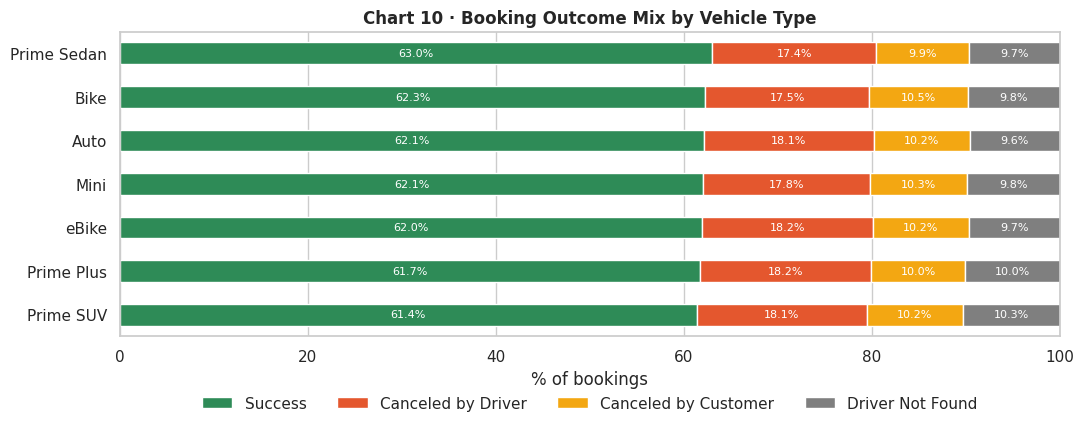

In [26]:
status_order = ["Success", "Canceled by Driver", "Canceled by Customer", "Driver Not Found"]
mix = pd.crosstab(clean["Vehicle_Type"], clean["Booking_Status"], normalize="index")[status_order] * 100
mix = mix.sort_values("Success", ascending=False)
print(mix.round(1))

ax = mix.plot(kind="barh", stacked=True, figsize=(11, 4.5),
              color=[STATUS_COLORS[s] for s in status_order], edgecolor="white")
for c in ax.containers:
    ax.bar_label(c, fmt="%.1f%%", label_type="center", fontsize=8, color="white")
ax.invert_yaxis(); ax.set_xlim(0, 100)
ax.set_xlabel("% of bookings"); ax.set_ylabel("")
ax.set_title("Chart 10 · Booking Outcome Mix by Vehicle Type", weight="bold")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=4, frameon=False)
plt.tight_layout(); plt.show()

**Insight:** Booking outcomes are almost the same for every vehicle type. Success rates range only from 61.4% (Prime SUV) to 63.0% (Prime Sedan), a gap of 1.6 percentage points. Driver cancellations stay between 17.4% and 18.2%, customer cancellations between 9.9% and 10.5%, and “Driver Not Found” between 9.6% and 10.3%. Premium vehicles do not cancel more or less than budget ones, and Prime SUV and Prime Plus have the slightly highest “Driver Not Found” rates (10.3% and 10.0%).

**So what:** the cancellation problem is company-wide, not tied to a particular vehicle category, so fixing one fleet type would not move the overall success rate. The small SUV and Prime Plus supply gap is the only hint of a vehicle-specific issue, and it is too small to act on alone.

**Action:** apply cancellation fixes (pickup tracking, driver penalties) across all vehicle types at once, and monitor the premium “Driver Not Found” rate monthly to see whether it grows into a real supply shortage.

#### Chart 11: Revenue and average fare by vehicle type

              Revenue  Rides  Avg_Fare  Avg_Km  Rev_Share_%
Vehicle_Type                                               
Prime Sedan   5224050   9379     557.0    25.0         14.9
eBike         5054662   9180     550.6    25.1         14.4
Auto          5051846   9167     551.1    10.0         14.4
Prime Plus    5015165   9075     552.6    25.0         14.3
Bike          4971968   9134     544.3    24.9         14.2
Mini          4885961   9036     540.7    25.0         13.9
Prime SUV     4876815   8996     542.1    24.9         13.9
Total revenue check: ₹ 35080467


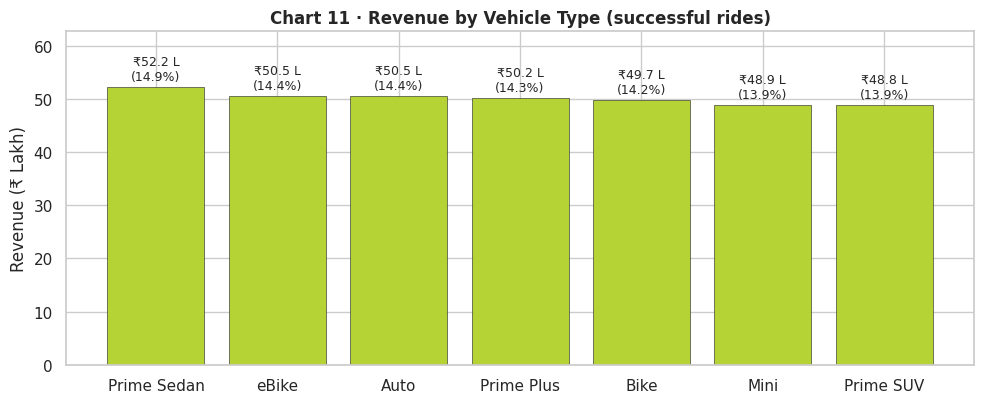

In [28]:
rev = (success.groupby("Vehicle_Type")
       .agg(Revenue=("Booking_Value", "sum"), Rides=("Booking_ID", "count"),
            Avg_Fare=("Booking_Value", "mean"), Avg_Km=("Ride_Distance", "mean"))
       .sort_values("Revenue", ascending=False))
rev["Rev_Share_%"] = (rev["Revenue"] / rev["Revenue"].sum() * 100).round(1)
print(rev.round(1)); print("Total revenue check: ₹", rev["Revenue"].sum())

fig, ax = plt.subplots(figsize=(10, 4.2))
bars = ax.bar(rev.index, rev["Revenue"] / 1e5, color=OLA_GREEN, edgecolor=OLA_BLACK, linewidth=0.4)
ax.bar_label(bars, labels=[f"₹{r/1e5:.1f} L\n({s}%)" for r, s in zip(rev["Revenue"], rev["Rev_Share_%"])],
             padding=3, fontsize=9)
ax.set_ylabel("Revenue (₹ Lakh)"); ax.set_ylim(0, rev["Revenue"].max() / 1e5 * 1.2)
ax.set_title("Chart 11 · Revenue by Vehicle Type (successful rides)", weight="bold")
plt.tight_layout(); plt.show()

**Insight:** Successful rides earned ₹3.51 Cr in total, split very evenly across vehicles: Prime Sedan leads with ₹52.2 L (14.9%) and Prime SUV is lowest with ₹48.8 L (13.9%). Prime Sedan leads only because it completed the most rides (9,379), not because it charges more, since average fares for all seven vehicles sit within ₹541–₹557. The real outlier is distance: Auto trips average only 10.0 km, while every other vehicle averages about 25 km. Autos still charge the same ≈ ₹551 fare, so they earn roughly 2.5 times more per km. This Auto group also explains the sudden drop at 20 km in the distance distribution (Chart 7).

**So what:** in this data, fares do not rise with distance or vehicle class (a Bike costs about the same as a Prime SUV), which does not match how any real ride service prices trips. Revenue differences between vehicles are therefore driven by ride count alone.

**Action:** treat vehicle-level revenue as “no meaningful difference”, investigate the Auto pricing anomaly (same fare for less than half the distance) as a potential overcharging or data-generation issue, and recommend that OLA audit its fare formula so fares scale with distance and vehicle class.

#### Chart 12: Fare vs distance and fare per km by vehicle

Correlation (fare vs distance): 0.002
Vehicle_Type
Auto           43.9
Prime Plus     18.0
Prime Sedan    17.8
Mini           17.8
Prime SUV      17.8
Bike           17.7
eBike          17.5
Name: Fare_per_km, dtype: float64


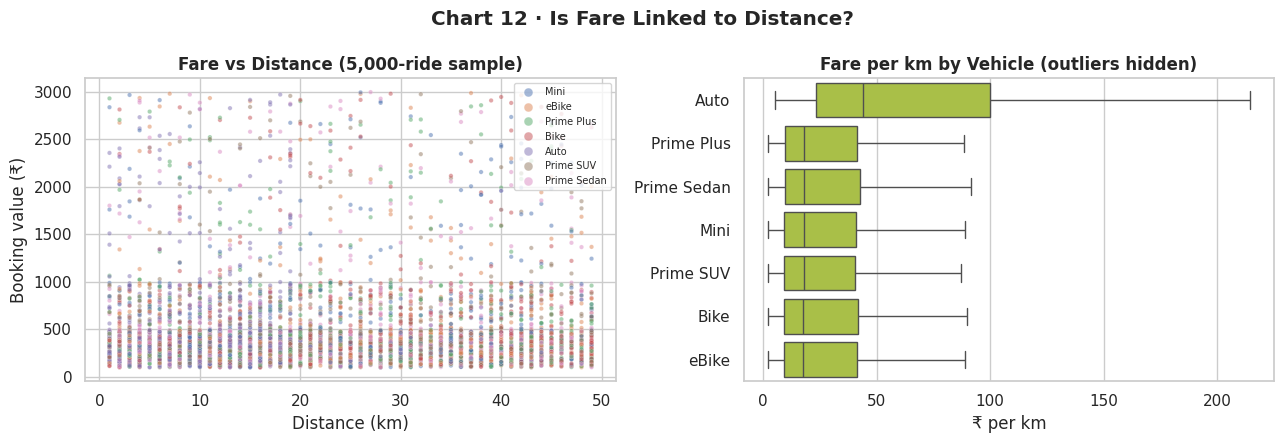

In [29]:
print("Correlation (fare vs distance):", round(success["Booking_Value"].corr(success["Ride_Distance"]), 3))
print(success.groupby("Vehicle_Type")["Fare_per_km"].median().sort_values(ascending=False).round(1))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

samp = success.sample(5000, random_state=42)          # 5,000 random dots so the chart stays readable
sns.scatterplot(data=samp, x="Ride_Distance", y="Booking_Value", hue="Vehicle_Type", s=10, alpha=0.5, ax=ax1)
ax1.set_title("Fare vs Distance (5,000-ride sample)", weight="bold")
ax1.set_xlabel("Distance (km)"); ax1.set_ylabel("Booking value (₹)")
ax1.legend(fontsize=7, markerscale=2)

order_fpk = success.groupby("Vehicle_Type")["Fare_per_km"].median().sort_values(ascending=False).index
sns.boxplot(data=success, x="Fare_per_km", y="Vehicle_Type", order=order_fpk, color=OLA_GREEN,
            showfliers=False, ax=ax2)                  # hide outlier dots to see the boxes clearly
ax2.set_title("Fare per km by Vehicle (outliers hidden)", weight="bold")
ax2.set_xlabel("₹ per km"); ax2.set_ylabel("")

fig.suptitle("Chart 12 · Is Fare Linked to Distance?", weight="bold")
plt.tight_layout(); plt.show()

**Insight:** Fare and distance have no relationship at all in this data. Their correlation is 0.002, so a 2 km ride and a 49 km ride cost the same on average, and the scatter plot shows flat horizontal bands instead of an upward trend. Fares fall into the same ₹100–1,000 bulk and thin ₹1,000–3,000 tail at every distance. As a result, Autos, whose trips average only 10 km, have a median fare of ₹43.9 per km, about 2.5 times the ₹17.5–18.0 per km of every other vehicle, and their fare-per-km range is far wider.

**So what:** in a real ride-hailing business, fare must rise with distance (and with vehicle class), so a zero correlation means either the pricing engine is broken or, more likely, the dataset was generated with fares independent of trips. Any per-km pricing analysis or revenue forecast based on distance would be meaningless here.

**Action:** flag “fare not linked to distance” as the most serious data-quality finding of the project, avoid building distance-based pricing or revenue models on this data, and recommend that OLA audit its fare formula, especially for Autos, where riders would effectively pay 2.5 times the market rate per km.

#### Chart 13: Revenue by payment method (ride share vs revenue share)

                 Revenue  Rides  Avg_Fare  Ride_Share_%  Rev_Share_%
Payment_Method                                                      
Cash            19260316  35022     549.9          54.8         54.9
UPI             14168436  25881     547.4          40.5         40.4
Credit Card      1312793   2435     539.1           3.8          3.7
Debit Card        338922    629     538.8           1.0          1.0
Total revenue check: ₹ 35080467


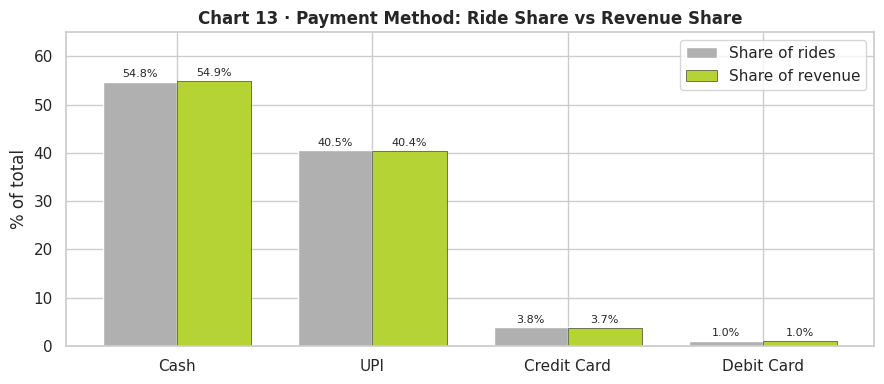

In [30]:
pm = (success.groupby("Payment_Method")
      .agg(Revenue=("Booking_Value", "sum"), Rides=("Booking_ID", "count"), Avg_Fare=("Booking_Value", "mean"))
      .sort_values("Revenue", ascending=False))
pm["Ride_Share_%"] = (pm["Rides"] / pm["Rides"].sum() * 100).round(1)
pm["Rev_Share_%"]  = (pm["Revenue"] / pm["Revenue"].sum() * 100).round(1)
print(pm.round(1)); print("Total revenue check: ₹", pm["Revenue"].sum())

x = np.arange(len(pm)); w = 0.38
fig, ax = plt.subplots(figsize=(9, 4))
b1 = ax.bar(x - w/2, pm["Ride_Share_%"], w, label="Share of rides",   color="#B0B0B0")
b2 = ax.bar(x + w/2, pm["Rev_Share_%"],  w, label="Share of revenue", color=OLA_GREEN, edgecolor=OLA_BLACK, linewidth=0.4)
ax.bar_label(b1, fmt="%.1f%%", padding=2, fontsize=8); ax.bar_label(b2, fmt="%.1f%%", padding=2, fontsize=8)
ax.set_xticks(x, pm.index); ax.set_ylabel("% of total"); ax.set_ylim(0, 65); ax.legend()
ax.set_title("Chart 13 · Payment Method: Ride Share vs Revenue Share", weight="bold")
plt.tight_layout(); plt.show()

**Insight:** Cash brings in the most revenue, ₹1.93 Cr (54.9% of the total), followed by UPI with ₹1.42 Cr (40.4%), while Credit Card (₹13.1 L, 3.7%) and Debit Card (₹3.4 L, 1.0%) contribute very little. Each method’s revenue share almost exactly matches its ride share, with the largest gap only 0.1 percentage points, because average fares are nearly identical across methods (₹539–₹550). Card users do not take more expensive rides.

**So what:** payment method affects how OLA collects money, not how much each ride is worth, so the business case for digital payments rests on cost and convenience (faster settlement, less cash handling, fewer change disputes) rather than higher fares. About ₹1.93 Cr a month is still collected in cash.

**Action:** focus digital-payment efforts on moving cash riders to UPI through small cashback offers or UPI-first defaults in the app, measure success by the drop in cash share rather than by fare changes, and do not expect card promotions to raise revenue per ride.

#### Chart 14: Success rate by pickup location (best 10 vs worst 10)

Locations: 50 | bookings per location: 1952 to 2201
Success rate range: 59.8% to 64.0% | std 0.99 pp


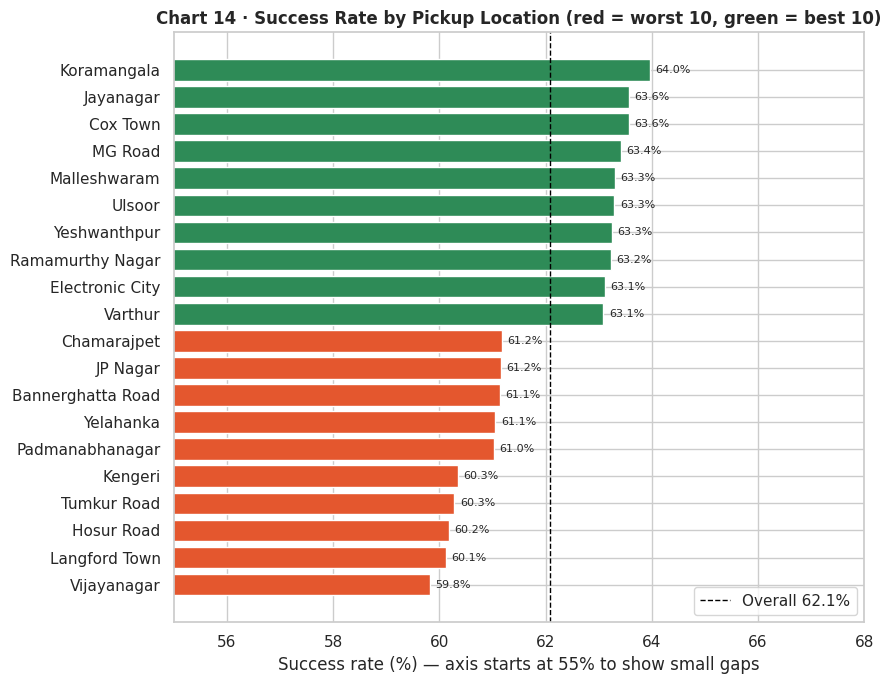

In [31]:
loc = (clean.groupby("Pickup_Location")
       .agg(Bookings=("Booking_ID", "count"), Success_Rate=("Is_Success", "mean"))
       .assign(Success_Rate=lambda d: d["Success_Rate"] * 100)
       .sort_values("Success_Rate"))
print("Locations:", len(loc), "| bookings per location:", loc["Bookings"].min(), "to", loc["Bookings"].max())
print("Success rate range: {:.1f}% to {:.1f}% | std {:.2f} pp".format(
      loc["Success_Rate"].min(), loc["Success_Rate"].max(), loc["Success_Rate"].std()))

show = pd.concat([loc.head(10), loc.tail(10)])
colors = ["#E4572E"] * 10 + ["#2E8B57"] * 10
fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(show.index, show["Success_Rate"], color=colors)
for i, v in enumerate(show["Success_Rate"]):
    ax.text(v + 0.1, i, f"{v:.1f}%", va="center", fontsize=8)
ax.axvline(clean["Is_Success"].mean() * 100, color="black", ls="--", lw=1, label="Overall 62.1%")
ax.set_xlim(55, 68)
ax.set_xlabel("Success rate (%) — axis starts at 55% to show small gaps")
ax.set_title("Chart 14 · Success Rate by Pickup Location (red = worst 10, green = best 10)", weight="bold")
ax.legend(loc="lower right"); plt.tight_layout(); plt.show()

**Insight:** Success rates across the 50 pickup locations range from 59.8% (Vijayanagar) to 64.0% (Koramangala), with a standard deviation of only 0.99 percentage points around the overall 62.1%. Each location has a similar volume of 1,952–2,201 bookings. At that size, random chance alone would make a location’s success rate vary by about ±1.1 points, so the observed spread is almost exactly what pure luck would produce. The “worst 10” (Vijayanagar, Langford Town, Hosur Road, Tumkur Road, Kengeri and others) and the “best 10” (Koramangala, Jayanagar, Cox Town, MG Road and others) are therefore not reliably different.

**So what:** there is no evidence of location-specific cancellation problems, so sending extra drivers or running local campaigns in the “red” areas would be acting on noise. The cancellation issue is city-wide, matching what we saw for hours, days and vehicles.

**Action: **apply cancellation fixes uniformly across Bengaluru, do not label any area as a problem zone based on one month of data, and monitor location success rates over several months, flagging an area only if it stays below the city average consistently.

#### Chart 15: Average driver and customer ratings by vehicle type

              Driver_Ratings  Customer_Rating    Gap
Vehicle_Type                                        
eBike                  4.007            3.988  0.019
Prime SUV              4.006            3.999  0.007
Auto                   4.004            3.999  0.005
Prime Plus             3.998            4.009 -0.011
Mini                   3.993            3.998 -0.005
Prime Sedan            3.991            4.002 -0.011
Bike                   3.985            3.993 -0.008


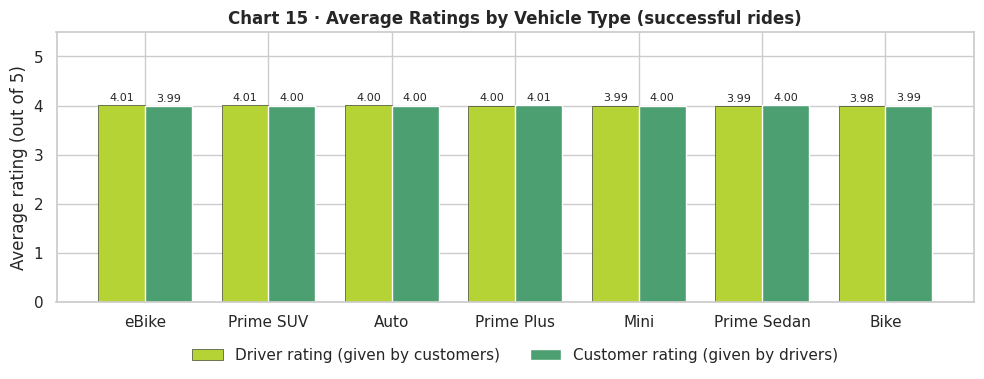

In [33]:
rt = (success.groupby("Vehicle_Type")[["Driver_Ratings", "Customer_Rating"]].mean()
      .sort_values("Driver_Ratings", ascending=False).round(3))
rt["Gap"] = (rt["Driver_Ratings"] - rt["Customer_Rating"]).round(3)
print(rt)

x = np.arange(len(rt)); w = 0.38
fig, ax = plt.subplots(figsize=(10, 4))
b1 = ax.bar(x - w/2, rt["Driver_Ratings"],  w, label="Driver rating (given by customers)", color=OLA_GREEN, edgecolor=OLA_BLACK, linewidth=0.4)
b2 = ax.bar(x + w/2, rt["Customer_Rating"], w, label="Customer rating (given by drivers)", color="#4C9F70")
ax.bar_label(b1, fmt="%.2f", padding=2, fontsize=8); ax.bar_label(b2, fmt="%.2f", padding=2, fontsize=8)
ax.set_xticks(x, rt.index); ax.set_ylim(0, 5.5); ax.set_ylabel("Average rating (out of 5)")
ax.set_title("Chart 15 · Average Ratings by Vehicle Type (successful rides)", weight="bold")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2, frameon=False), plt.tight_layout(); plt.show()

**Insight:** Average ratings are virtually identical across all seven vehicle types. Driver ratings (given by customers) range only from 3.985 (Bike) to 4.007 (eBike), and customer ratings (given by drivers) from 3.988 (eBike) to 4.009 (Prime Plus), a spread of about 0.02 stars on a 5-star scale. The gap between how customers rate drivers and how drivers rate customers is never more than ±0.02 for any vehicle. With around 9,000 rides per vehicle, differences this small are within normal random variation.

**So what:** premium vehicles do not deliver a better rated experience than budget ones, and neither side rates the other more harshly, so ratings cannot be used to rank vehicle categories or justify premium pricing in this data.

**Action:** report ratings by vehicle as “no meaningful difference”, avoid quality rewards or penalties by vehicle type based on these numbers, and recommend collecting richer feedback (written reviews, complaint categories, low-rating reasons) to find real service-quality gaps.

### 5.3 Multivariate analysis (three or more variables)
#### Chart 16: Demand heatmap — hour of day × day of week

Avg bookings per hour-slot: 138.4
Cell range: 125 to 154 | deviation range: -9.7% to +11.6%


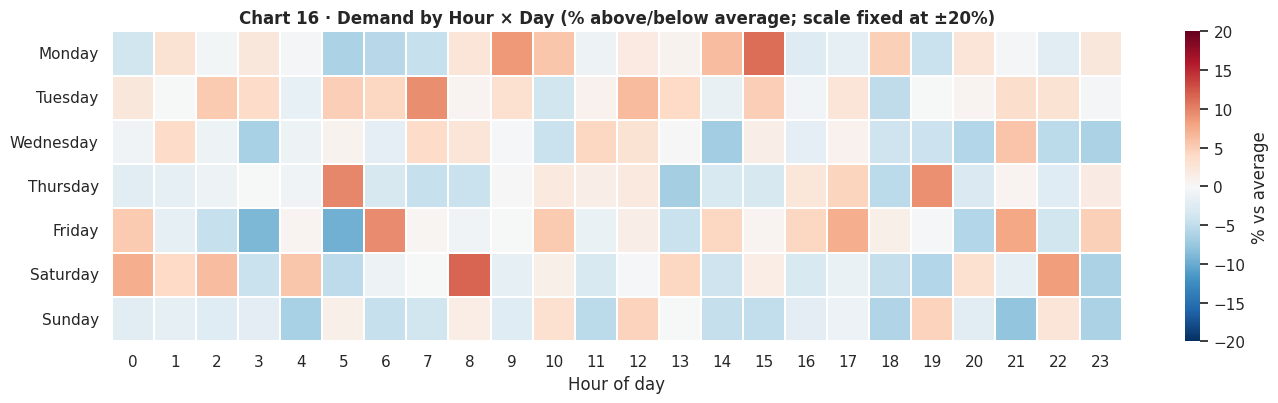

In [34]:
days_in_july = daily["Day_Name"].value_counts()                       # 5 Mon/Tue/Wed, 4 others
grid = clean.groupby(["Day_Name", "Ride_Hour"]).size().unstack()      # rows = days, columns = hours
grid = grid.div(days_in_july, axis=0).reindex(order)                  # average bookings per occurrence
pct_dev = (grid / grid.values.mean() - 1) * 100                       # % above/below overall average

print("Avg bookings per hour-slot:", round(grid.values.mean(), 1))
print("Cell range: {:.0f} to {:.0f} | deviation range: {:+.1f}% to {:+.1f}%".format(
      grid.values.min(), grid.values.max(), pct_dev.values.min(), pct_dev.values.max()))

fig, ax = plt.subplots(figsize=(14, 4.2))
sns.heatmap(pct_dev, cmap="RdBu_r", center=0, vmin=-20, vmax=20, linewidths=0.3,
            cbar_kws={"label": "% vs average"}, ax=ax)
ax.set_title("Chart 16 · Demand by Hour × Day (% above/below average; scale fixed at ±20%)", weight="bold")
ax.set_xlabel("Hour of day"); ax.set_ylabel("")
plt.tight_layout(); plt.show()

**Insight:** Across all 168 combinations of weekday and hour, average demand per slot is 138.4 bookings, and every cell stays within −9.7% to +11.6% of that average. The few stronger cells (for example Monday 15:00, Saturday 08:00 and Thursday 05:00) appear as isolated squares rather than as consistent rows or columns: no hour is busy on every day, and no day is busy at every hour. Since each cell is based on only about 550–690 bookings, random variation alone would produce extremes of roughly ±11%, which matches what we see.

**So what:** combining hour and weekday reveals no hidden rush periods that the single-variable charts missed. Demand in this dataset is evenly spread across the whole week, so time-based surge pricing or shift planning has no support here.

**Action:** schedule drivers evenly across all hours and days for this data, use this heatmap layout as a monitoring tool on real data (where genuine weekday rush-hour blocks would show up as solid red bands), and avoid reacting to single bright cells, which are noise.

#### Chart 17: Correlation heatmap — numeric variables (successful rides)
Note: V_TAT and C_TAT are recorded only for successful rides, so the link between
wait time and cancellation cannot be tested with this data.

Strongest pairs:
 Booking_Value  Fare_per_km      0.40
Ride_Distance  Fare_per_km      0.38
               V_TAT            0.01
               Booking_Value    0.00
dtype: float64


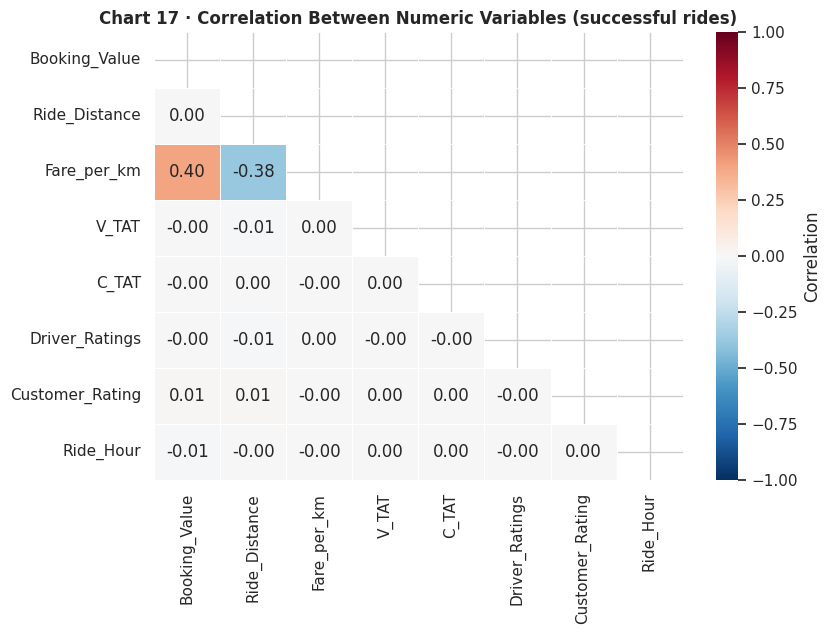

In [35]:
num_cols = ["Booking_Value", "Ride_Distance", "Fare_per_km", "V_TAT", "C_TAT",
            "Driver_Ratings", "Customer_Rating", "Ride_Hour"]
corr = success[num_cols].corr().round(2)

off_diag = corr.where(~np.eye(len(corr), dtype=bool)).stack()   # every pair except a column with itself
print("Strongest pairs:\n", off_diag.abs().sort_values(ascending=False).drop_duplicates().head(5))

fig, ax = plt.subplots(figsize=(8.5, 6.5))
mask = np.triu(np.ones_like(corr, dtype=bool))                  # hide the upper triangle (mirror copy)
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            linewidths=0.5, cbar_kws={"label": "Correlation"}, ax=ax)
ax.set_title("Chart 17 · Correlation Between Numeric Variables (successful rides)", weight="bold")
plt.tight_layout(); plt.show()

**Insight:** Among eight numeric variables for completed rides, the only notable correlations are Fare_per_km with Booking_Value (+0.40) and with Ride_Distance (−0.38), and both are mechanical, because Fare_per_km is calculated as fare divided by distance. Every other pair is effectively zero (between −0.01 and +0.01): fare is unrelated to distance, wait times (V_TAT, C_TAT) are unrelated to driver or customer ratings, the two time measures are unrelated to each other, and nothing varies with the hour of the booking. Because V_TAT and C_TAT are recorded only for successful rides, the link between waiting time and cancellation cannot be tested at all.

**So what:** in real ride-hailing data, longer trips cost more and longer waits lead to lower ratings and more cancellations. Their complete absence here confirms that each column was generated independently, so no variable can predict another, and building predictive models on this data would be pointless.

**Action:** state clearly in the report that the numeric variables are independent and that relationships such as wait time → rating or wait time → cancellation cannot be tested, and recommend that OLA log pickup wait times for cancelled bookings too, so the impact of delays on cancellations can be measured in the future.

#### Chart 18: Potential fare value lost by vehicle and outcome (non-successful bookings)
Booking_Value on cancelled rides is a quoted fare, not money earned. This chart shows
revenue *at risk*, not revenue lost from accounts.

Quoted value of non-successful bookings: ₹ 21454147 (≈ ₹2.15 Cr)
As % of (earned + lost): 37.9%
Booking_Status
Canceled by Customer     57.7
Canceled by Driver      101.8
Driver Not Found         55.0
Name: Booking_Value, dtype: float64


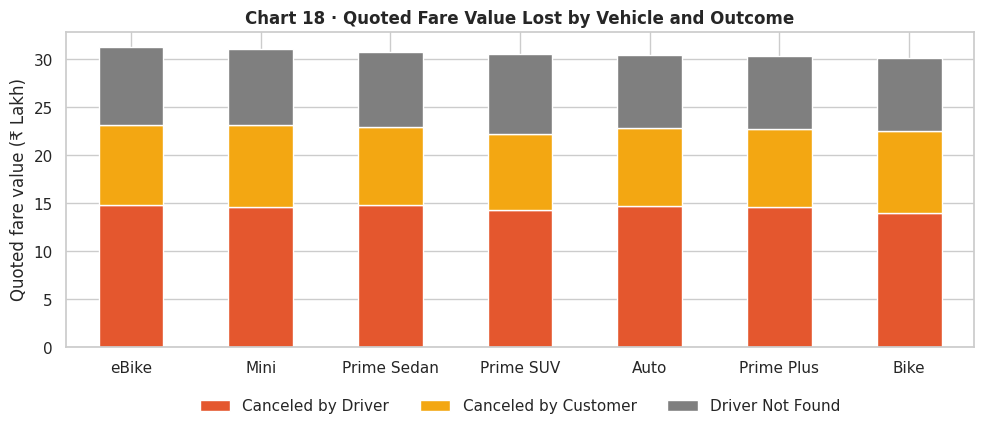

In [36]:
lost = clean[clean["Is_Success"] == 0]
lost_tbl = (lost.pivot_table(index="Vehicle_Type", columns="Booking_Status",
                             values="Booking_Value", aggfunc="sum")
            [["Canceled by Driver", "Canceled by Customer", "Driver Not Found"]] / 1e5)
lost_tbl = lost_tbl.loc[lost_tbl.sum(axis=1).sort_values(ascending=False).index]

total_lost = lost["Booking_Value"].sum()
print("Quoted value of non-successful bookings: ₹", total_lost, f"(≈ ₹{total_lost/1e7:.2f} Cr)")
print("As % of (earned + lost): {:.1f}%".format(total_lost / (total_lost + success['Booking_Value'].sum()) * 100))
print((lost.groupby("Booking_Status")["Booking_Value"].sum() / 1e5).round(1))

ax = lost_tbl.plot(kind="bar", stacked=True, figsize=(10, 4.5),
                   color=[STATUS_COLORS[c] for c in lost_tbl.columns], edgecolor="white")
ax.set_ylabel("Quoted fare value (₹ Lakh)"); ax.set_xlabel("")
ax.set_title("Chart 18 · Quoted Fare Value Lost by Vehicle and Outcome", weight="bold")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=3, frameon=False)
plt.xticks(rotation=0); plt.tight_layout(); plt.show()

**Insight:** Non-successful bookings carried quoted fares worth ₹2.15 Cr, compared with ₹3.51 Cr actually earned, so 37.9% of all potential fare value was lost in July. Driver cancellations account for the largest share, ₹1.02 Cr (47.5% of the lost value), followed by customer cancellations (₹57.7 L) and “Driver Not Found” (₹55.0 L). The loss is spread almost evenly across vehicles (about ₹30–31 L each, from eBike at the top to Bike at the bottom), and the split between the three failure types looks the same for every vehicle.

**So what:** cancellations are not just an operational nuisance. They put roughly ₹2 Cr per month of potential revenue at risk, and nearly half of that is controlled by drivers. Because the pattern is identical for every vehicle, the fix must be platform-wide rather than fleet-specific. (This is quoted value, not booked revenue, so it is an upper limit, not a guaranteed gain.)

**Action:** use “revenue at risk” as the business case for cancellation fixes. Even recovering one-fifth of driver cancellations would protect about ₹20 L a month. Prioritise driver-side measures (pickup tracking, cancellation penalties, acceptance incentives) and add more driver supply to recover part of the ₹55 L lost to “Driver Not Found”.

#### Chart 19: Anomalies — same pickup & drop location and fare-per-km extremes

                     Bookings  Success_Rate_%  Avg_Km (success)  Avg_Fare (success)
Same pickup & drop       2121            61.6              22.7               540.9
Different locations    100903            62.1              22.9               548.6

Fare per km — 1st pct: ₹2.9 | median: ₹20.4 | 99th pct: ₹641.0 | max: ₹2981.0
Rides above ₹200/km: 3591
      Vehicle_Type  Ride_Distance  Booking_Value  Fare_per_km
58836        eBike              1           2981       2981.0
32168         Auto              1           2940       2940.0
8562    Prime Plus              1           2932       2932.0
7397          Auto              1           2928       2928.0
8446         eBike              1           2920       2920.0


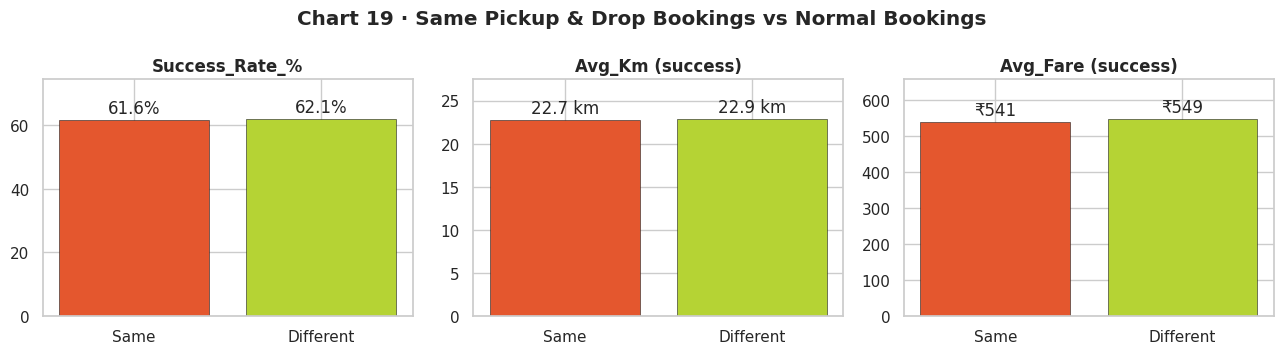

In [37]:
same = clean["Same_Pickup_Drop"] == 1
cmp = pd.DataFrame({
    "Bookings":         [same.sum(), (~same).sum()],
    "Success_Rate_%":   [clean.loc[same, "Is_Success"].mean() * 100, clean.loc[~same, "Is_Success"].mean() * 100],
    "Avg_Km (success)": [success.loc[success["Same_Pickup_Drop"] == 1, "Ride_Distance"].mean(),
                         success.loc[success["Same_Pickup_Drop"] == 0, "Ride_Distance"].mean()],
    "Avg_Fare (success)": [success.loc[success["Same_Pickup_Drop"] == 1, "Booking_Value"].mean(),
                           success.loc[success["Same_Pickup_Drop"] == 0, "Booking_Value"].mean()],
}, index=["Same pickup & drop", "Different locations"]).round(1)
print(cmp)

fpk = success["Fare_per_km"]
print("\nFare per km — 1st pct: ₹{:.1f} | median: ₹{:.1f} | 99th pct: ₹{:.1f} | max: ₹{:.1f}".format(
      fpk.quantile(0.01), fpk.median(), fpk.quantile(0.99), fpk.max()))
print("Rides above ₹200/km:", (fpk > 200).sum())
print(success.nlargest(5, "Fare_per_km")[["Vehicle_Type", "Ride_Distance", "Booking_Value", "Fare_per_km"]])

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, col, fmt in zip(axes, ["Success_Rate_%", "Avg_Km (success)", "Avg_Fare (success)"], ["%.1f%%", "%.1f km", "₹%.0f"]):
    b = ax.bar(["Same", "Different"], cmp[col], color=["#E4572E", OLA_GREEN], edgecolor=OLA_BLACK, linewidth=0.4)
    ax.bar_label(b, fmt=fmt, padding=2); ax.set_title(col, weight="bold"); ax.set_ylim(0, cmp[col].max() * 1.2)
fig.suptitle("Chart 19 · Same Pickup & Drop Bookings vs Normal Bookings", weight="bold")
plt.tight_layout(); plt.show()

**Insight:** 2,121 bookings (2.1%) have the same pickup and drop location, yet they look exactly like normal bookings: a 61.6% success rate (vs 62.1%), an average completed distance of 22.7 km (vs 22.9 km) and an average fare of ₹541 (vs ₹549). A trip that starts and ends at the same place but covers 22.7 km would have to be a round trip, and nothing in the data marks round trips. Fare-per-km shows a more serious anomaly: the middle 98% of completed rides cost between ₹2.9 and ₹641 per km (median ₹20.4), but 3,591 rides (5.6%) cost more than ₹200 per km, and the five most extreme are 1 km trips charged ₹2,920–₹2,981.

**So what:** same-location trips are a data-quality issue (missing trip type or location errors) rather than evidence of fraud, but fares of nearly ₹3,000 for 1 km would be serious overcharging in a real business and would distort any per-km pricing analysis.

**Action:** add a “round trip” flag and a location check to the booking system, set an automatic alert for any completed ride above a fare-per-km threshold (for example ₹200/km) for manual review, and exclude these extreme fares when setting price benchmarks while keeping them in revenue totals, since the money was actually charged.

## 6. Key Findings

**Business performance (July 2024, Bengaluru)**
1. **103,024 bookings → 63,967 completed (62.1%)**, earning **₹3.51 Cr** in revenue.
2. **Cancellation rate is 28.1%**: drivers cancelled 17.9% of bookings and customers 10.2%. Another **9.8% failed because no driver was found** (supply gap).
3. **Drivers are the main cause of cancellations.** Over half of customer cancellations are driver-caused ("driver not moving", "driver asked to cancel"), so about **84% of all cancellations trace back to driver behaviour**.
4. **₹2.15 Cr of quoted fares were lost** to failed bookings (37.9% of potential value); driver cancellations alone account for **₹1.02 Cr**.
5. **Cash dominates payments (54.8% of rides, ₹1.93 Cr)**, UPI follows (40.5%), and cards are under 5%. Average fares are the same for every method.

**What did NOT differ (honest "no meaningful difference" findings)**
6. **Demand is flat** across hours (peak only 5.6% above the lowest), days (4.1% gap) and their combination (heatmap within ±12%, consistent with chance).
7. **Vehicle types are almost identical** in bookings (14.1–14.4% each), success rate (61.4–63.0%), revenue share (13.9–14.9%) and ratings (all ≈ 4.00).
8. **Pickup locations** differ by only 4.2 points in success rate, which matches random variation at ~2,000 bookings per location.
9. **Ratings are uniform** between 3.0 and 5.0 (mean 4.00 for both drivers and customers), with no low ratings and no 5-star cluster.

**Data-quality findings**
10. **Fare is not linked to distance** (correlation 0.002), so **Autos average 10 km but charge the same ≈ ₹551**, which is ~2.5× more per km.
11. **5.6% of completed rides cost over ₹200/km**; the most extreme are 1 km trips at ~₹2,950.
12. **2.1% of bookings** have the same pickup and drop location but normal 22.7 km distances.
13. Wait times (V_TAT, C_TAT) exist **only for completed rides**, so their effect on cancellations **cannot be tested**.
14. The even splits, step-shaped distributions, rounding artefacts in ratings and near-zero correlations indicate the dataset is **synthetic**; conclusions describe this data, not real OLA operations.

## 7. Recommendations

| # | Recommendation | Based on | Expected impact |
|---|---|---|---|
| 1 | **Reduce driver cancellations**: live pickup tracking with alerts when a driver is not moving, penalties for repeated driver cancellations, and acceptance incentives | Charts 1, 9, 18 | Largest controllable loss; recovering 20% of driver cancellations would protect ≈ ₹20 L/month in quoted fares |
| 2 | **Close the supply gap**: driver positioning and incentives to cut "Driver Not Found" (9.8%) | Charts 1, 18 | Up to ₹55 L/month of quoted fares at risk |
| 3 | **Vehicle quality checks**: AC and car-condition checks to cut "AC not working" and "car-related" cancellations | Chart 9 | Targets 1,568 customer and part of 6,542 driver cancellations |
| 4 | **Shift cash riders to UPI** with small cashback or UPI-first defaults; track cash share as the KPI | Charts 5, 13 | Faster settlement, less cash risk for drivers; no change in fare expected |
| 5 | **Audit the fare formula**: fares must rise with distance and vehicle class; review Auto pricing | Charts 11, 12 | Fixes ~2.5× per-km overcharge on Autos |
| 6 | **Automatic anomaly alerts**: review any ride above ₹200/km; add a round-trip flag and location validation | Chart 19 | Catches overcharging and data errors early |
| 7 | **Log wait times for cancelled bookings** and collect detailed rating feedback | Charts 8, 17 | Makes cancellation and service-quality causes measurable |
| 8 | **Plan supply evenly** across hours, days, vehicles and locations for now; re-test with several months of real data before time- or area-based pricing | Charts 2, 3, 4, 14, 16 | Avoids acting on noise |

## 8. Export cleaned data for the MySQL pipeline

In [38]:
export = clean.copy()
export["Is_Weekend"] = export["Is_Weekend"].astype(int)          # True/False → 1/0 for MySQL
export.to_csv("ola_cleaned.csv", index=False)
icons.to_csv("vehicle_icons.csv", index=False)

check = pd.read_csv("ola_cleaned.csv")
print("Saved:", check.shape, "| Revenue check: ₹", check["Revenue"].sum())

from google.colab import files
files.download("ola_cleaned.csv"); files.download("vehicle_icons.csv")

Saved: (103024, 33) | Revenue check: ₹ 35080467


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>